**Program name:** GNS1 - Applications of generative models to enhance the performance of complex probabilistic seismic models

**Student names - IDs:**

  - Martin Nguyen - 68623131
  - Jian Di - 61972461

**Descriptions:**  To reduce the complexity of probabilistic seismic models as well as the amount of computation time and operation work from PHSA process in OpenQuake Engine, this three-month project has been proposed to apply Generative Adversarial Network model, Conditional Tabular Generative Adversarial Network (CTGAN) model in particular. The idea is that the CTGAN model will learn the underlying features from a small sample (about 10-20%) of the entire outputs produced by OpenQuake Engine to generate a similar outcome of the whole data. The performance would be measured by several different evaluation methods to see how the similarity would be. There would be 3 script reports:
- The script report 1 - Main script for the project
- The script report 2 - PGA transformation according to the Project Advisor
- The script report 3 - Trying the script on the full dataset


--------------------------------------------------------------------------------


This is the script report 2. The purpose of this report was to show that the model could learn the features of PGA after transforming PGA. However, it only succeeded to show the patterns in the Mapping method. Particularly, the transformation increased the variance and made the outliers disappear. This helped the model learn the patterns easier. However, when the values were inversed to the original format, the results still showed that the model could not learn the PGA.

The transformation was processed in the modelling part, before putting the training sample into the model.

**DATA ETHICS**

In [ ]:
# Installing deon
!pip install deon

In [ ]:
# Creating checklist file
!deon -o ETHICS_CHECKLIST.md

Checklist successfully written to file ETHICS_CHECKLIST.md.


In [ ]:
# Calling out the file
!cat ETHICS_CHECKLIST.md

# Data Science Ethics Checklist

[![Deon badge](https://img.shields.io/badge/ethics%20checklist-deon-brightgreen.svg?style=popout-square)](http://deon.drivendata.org/)

## A. Data Collection
 - [ ] **A.1 Informed consent**: If there are human subjects, have they given informed consent, where subjects affirmatively opt-in and have a clear understanding of the data uses to which they consent?
 - [ ] **A.2 Collection bias**: Have we considered sources of bias that could be introduced during data collection and survey design and taken steps to mitigate those?
 - [ ] **A.3 Limit PII exposure**: Have we considered ways to minimize exposure of personally identifiable information (PII) for example through anonymization or not collecting information that isn't relevant for analysis?
 - [ ] **A.4 Downstream bias mitigation**: Have we considered ways to enable testing downstream results for biased outcomes (e.g., collecting data on protected group status like race or gender)?

## B. Data Storage


--------------------------------------------------------------------------------

# **1. DIRECTORY**

In [ ]:
# Checking if GPU was on
import tensorflow as tf
tf.test.gpu_device_name()

'/device:GPU:0'

In [ ]:
# Accessing to Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Changing the directory
%cd /content/drive/My\ Drive/Earthquake/for_Martin_and_Jian

# Building up the output directory
from pathlib import Path
output_directory = Path('/content/drive/My Drive/Earthquake/for_Martin_and_Jian')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/Earthquake/for_Martin_and_Jian


# **2. DATA HANDLING BEFORE MODELING**

## 2.1. Loading data

In [ ]:
# Loading csv file
import pandas as pd
HawkesBay_data_full = pd.read_csv("OQ_data_HawkesBay_region.csv")

# Checking data
HawkesBay_data_full

,Unnamed: 0,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
0,0,0,1244.0,0.010817,530.593,0.915348,90.217180,177.362655,-38.809237
1,1,0,1256.0,0.010859,635.389,0.744794,46.398606,177.482655,-38.809237
2,2,0,1261.0,0.010780,1000.000,0.443316,8.266183,177.532655,-38.809237
3,3,0,1466.0,0.010998,1000.000,0.443316,8.266183,177.592655,-38.829237
4,4,0,1561.0,0.013426,1000.000,0.443316,8.266183,177.472655,-38.839237
...,...,...,...,...,...,...,...,...,...
1927169,1927169,996,9186.0,0.011678,1000.000,0.443316,8.266183,176.192655,-39.459237
1927170,1927170,996,9195.0,0.011773,1000.000,0.443316,8.266183,176.282655,-39.459237
1927171,1927171,996,9199.0,0.014754,1000.000,0.443316,8.266183,176.322655,-39.459237
1927172,1927172,996,9200.0,0.012995,1000.000,0.443316,8.266183,176.332655,-39.459237


## 2.2. Data summary

In [ ]:
# Changing the name of the first column into order
HawkesBay_data_full = HawkesBay_data_full.rename(columns={'Unnamed: 0': 'order'})

# Checking details of data
HawkesBay_data_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1927174 entries, 0 to 1927173
Data columns (total 9 columns):
 #   Column    Dtype  
---  ------    -----  
 0   order     int64  
 1   event_id  int64  
 2   site_id   float64
 3   gmv_PGA   float64
 4   Vs30      float64
 5   Z2.5      float64
 6   Z1.0      float64
 7   lon       float64
 8   lat       float64
dtypes: float64(7), int64(2)
memory usage: 132.3 MB


### 2.2.1. Missing values

In [ ]:
# Checking missing values
num_missing = HawkesBay_data_full.isnull().values.sum()
print('Number of missing values: ', num_missing)

# Displaying missing values (if any)
HawkesBay_data_full[pd.isnull(HawkesBay_data_full["site_id"])]

Number of missing values:  7


,order,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
1927173,1927173,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Removing the missing value
HawkesBay_data_full = HawkesBay_data_full.drop([1927173])

# Checking data
HawkesBay_data_full.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1927173 entries, 0 to 1927172
Data columns (total 9 columns):
 #   Column    Dtype  
---  ------    -----  
 0   order     int64  
 1   event_id  int64  
 2   site_id   float64
 3   gmv_PGA   float64
 4   Vs30      float64
 5   Z2.5      float64
 6   Z1.0      float64
 7   lon       float64
 8   lat       float64
dtypes: float64(7), int64(2)
memory usage: 147.0 MB


### 2.2.2. Correlation

In [ ]:
# Creating function to show the correlation matrix heatmap of a dataframe
# Importing seaborn and matplotlib for using heatmap
import seaborn as sns
import matplotlib.pyplot as plt

# Creating function
def corr_heatmap(df, title):
  '''This function is to show the correlation matrix heatmap of a dataframe.
  For more details please visit: https://datatofish.com/correlation-matrix-pandas/
                                 https://datascience.stackexchange.com/questions/17540/make-seaborn-heatmap-bigger 
  Arguments:
            df:
              Dataframe needs to calculate the correlation matrix
            title:
              Name of the dataframe
  '''
  plt.figure(figsize=(10,10))
  sns.heatmap(df.corr(), annot_kws={"size": 15}, annot=True, cmap="YlGnBu").set_title(f'Correlation matrix of {title}')
  plt.show()

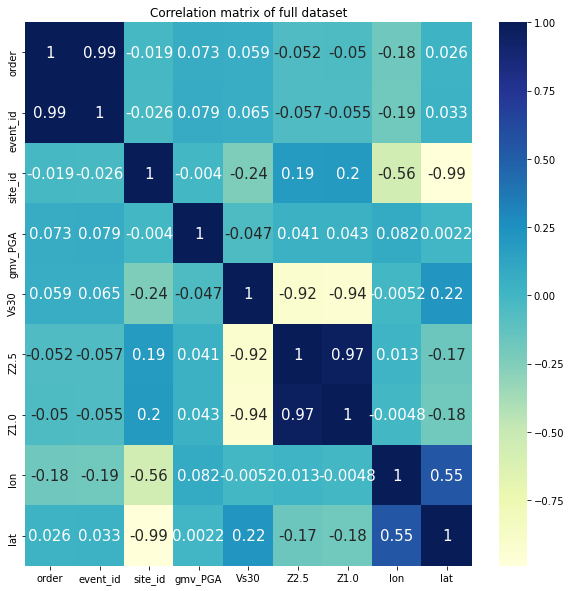

In [ ]:
# Checking correlation
corr_heatmap(HawkesBay_data_full, 'full dataset')

### 2.2.3. Variances

In [ ]:
# Checking variance of variables
print('Variance of event_id: ', HawkesBay_data_full.var()['event_id'])
print('Variance of site_id: ', HawkesBay_data_full.var()['site_id'])
print('Variance of PGA: ', HawkesBay_data_full.var()['gmv_PGA'])
print('Variance of Vs30: ', HawkesBay_data_full.var()['Vs30'])
print('Variance of Z2.5: ', HawkesBay_data_full.var()['Z2.5'])
print('Variance of Z1.0: ', HawkesBay_data_full.var()['Z1.0'])
print('Variance of lon: ', HawkesBay_data_full.var()['lon'])
print('Variance of lat: ', HawkesBay_data_full.var()['lat'])

Variance of event_id:  70395.65112233695
Variance of site_id:  21939811.517852794
Variance of PGA:  0.0004955774281478562
Variance of Vs30:  69194.80803572982
Variance of Z2.5:  0.3905959643205111
Variance of Z1.0:  11291.573466304819
Variance of lon:  0.19675849272752186
Variance of lat:  0.2188909648144187


### 2.2.4. Distributions



Text(0.5, 0.98, 'Distribution of variables in full dataset')

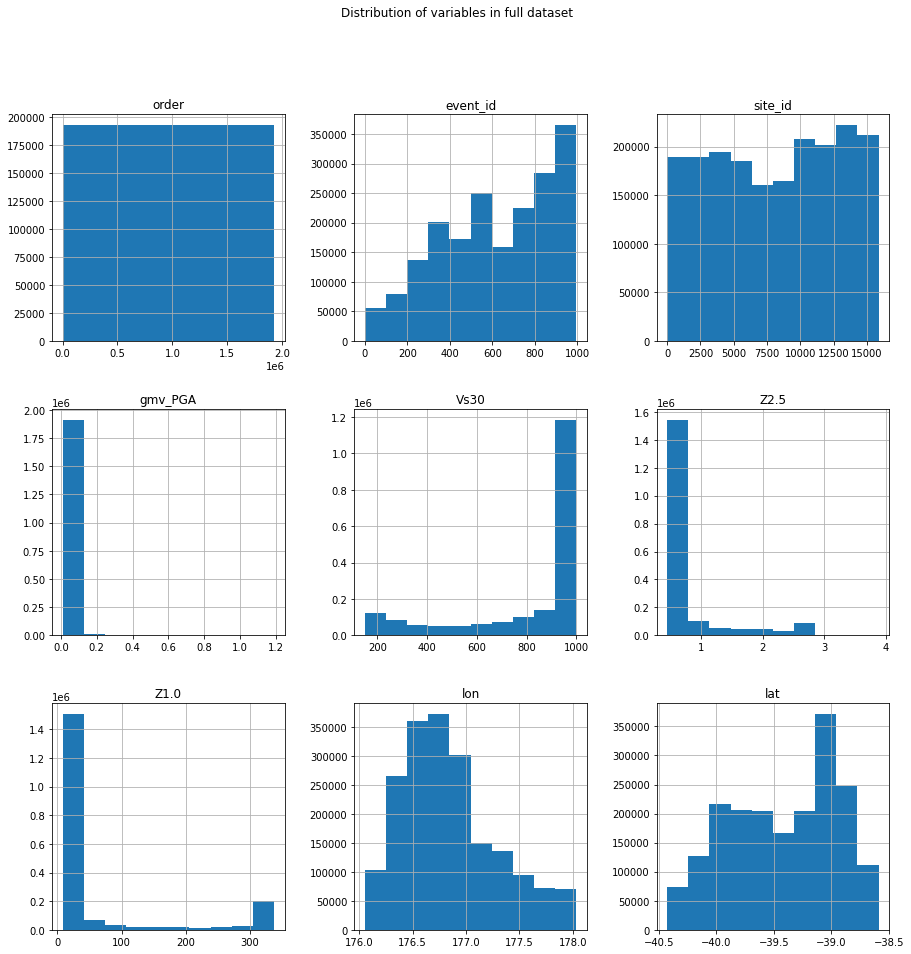

In [ ]:
# Checking distributions
HawkesBay_data_full.hist(figsize=(15, 15))
plt.suptitle('Distribution of variables in full dataset')

### 2.2.5. Other statistical summary

In [ ]:
# Checking the general statistical summary
HawkesBay_data_full.drop(columns=['order']).describe()

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
count,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06
mean,6.201857e+02,8.168213e+03,2.530335e-02,8.239278e+02,7.451369e-01,5.977937e+01,1.768460e+02,-3.941956e+01
std,2.653218e+02,4.683995e+03,2.226157e-02,2.630491e+02,6.249768e-01,1.062618e+02,4.435747e-01,4.678578e-01
min,0.000000e+00,0.000000e+00,1.000000e-02,1.500000e+02,4.433162e-01,8.266183e+00,1.760527e+02,-4.042924e+01
25%,4.010000e+02,4.050000e+03,1.299682e-02,7.252880e+02,4.433162e-01,8.266183e+00,1.765127e+02,-3.981924e+01
50%,6.260000e+02,8.394000e+03,1.804735e-02,9.883010e+02,4.493247e-01,8.646085e+00,1.767727e+02,-3.935924e+01
75%,8.510000e+02,1.234400e+04,2.882650e-02,1.000000e+03,6.401615e-01,2.812550e+01,1.770927e+02,-3.901924e+01
max,9.960000e+02,1.587700e+04,1.188596e+00,1.000000e+03,3.883874e+00,3.374264e+02,1.780327e+02,-3.858924e+01


In [ ]:
# Creating function to show the boxplots of variables in a dataframe at the same time
# Importing seaborn and matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

# Creating function
def full_boxplots(df, whisker, title):
  '''This function is to show the boxplots of variables in a dataframe at the same time
  For more details please visit: https://seaborn.pydata.org/generated/seaborn.boxplot.html 
  Arguments:
            df:
              Dataframe having variables needs to show the boxplots
            whisker:
              Proportion of the IQR past the low and high quartiles to extend the plot whiskers. 
              Points outside this range will be identified as outliers
            title:
              Name of dataframe
  '''
  plt.figure(figsize=(10,10))
  sns.boxplot(data=df, whis=whisker).set_title(f'Boxplots of {title}')
  plt.show()

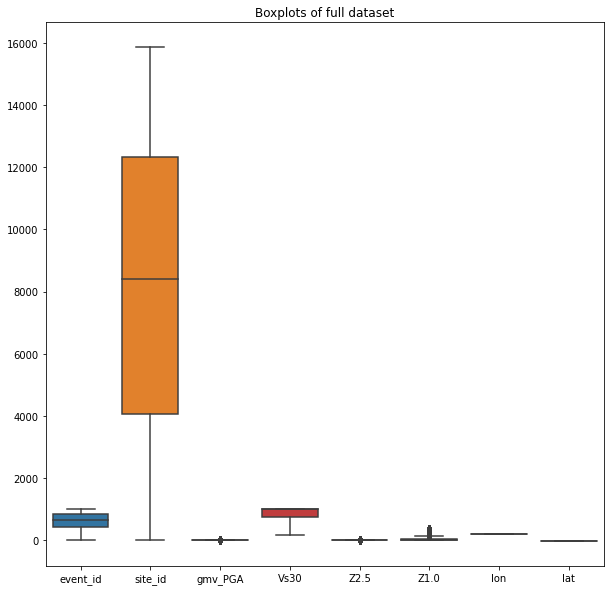

In [ ]:
# Checking the boxplots
full_boxplots(HawkesBay_data_full.drop(columns=['order']), 5, 'full dataset')

In [ ]:
# Creating function to show the boxplots of each variables in a dataframe
# Importing seaborn and matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

# Creating function
def each_boxplot(df, whisker, lonlat):
  '''This function is to show the boxplots of each variables in a dataframe.
  For more details please visit: https://seaborn.pydata.org/generated/seaborn.boxplot.html 
  Arguments:
            df:
              Dataframe having variables needs to show the boxplots
            whisker:
              Proportion of the IQR past the low and high quartiles to extend the plot whiskers. 
              Points outside this range will be identified as outliers
            lonlat ('y' or 'n'):
              y - yes for showing the boxplots of longitude and latitude
              n - no for showing the boxplots of longitude and latitude
  '''
  if lonlat == 'y':
    # if longitude and latitude needs showing the boxplots
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 15))

    sns.boxplot(data=df[['gmv_PGA']], whis=whisker, ax=axes[0,0]).set_title(f'Boxplot of PGA')
    sns.boxplot(data=df[['Vs30']], whis=whisker, ax=axes[0,1]).set_title(f'Boxplot of Vs30')
    sns.boxplot(data=df[['Z2.5']], whis=whisker, ax=axes[1,0]).set_title(f'Boxplot of Z2.5')
    sns.boxplot(data=df[['Z1.0']], whis=whisker, ax=axes[1,1]).set_title(f'Boxplot of Z1.0')
    sns.boxplot(data=df[['lon']], whis=whisker, ax=axes[2,0]).set_title(f'Boxplot of longitude')
    sns.boxplot(data=df[['lat']], whis=whisker, ax=axes[2,1]).set_title(f'Boxplot of latitude')
  else:
    # if longitude and latitude not need showing the boxplots
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 15))

    sns.boxplot(data=df[['gmv_PGA']], whis=whisker, ax=axes[0,0]).set_title(f'Boxplot of PGA')
    sns.boxplot(data=df[['Vs30']], whis=whisker, ax=axes[0,1]).set_title(f'Boxplot of Vs30')
    sns.boxplot(data=df[['Z2.5']], whis=whisker, ax=axes[1,0]).set_title(f'Boxplot of Z2.5')
    sns.boxplot(data=df[['Z1.0']], whis=whisker, ax=axes[1,1]).set_title(f'Boxplot of Z1.0')


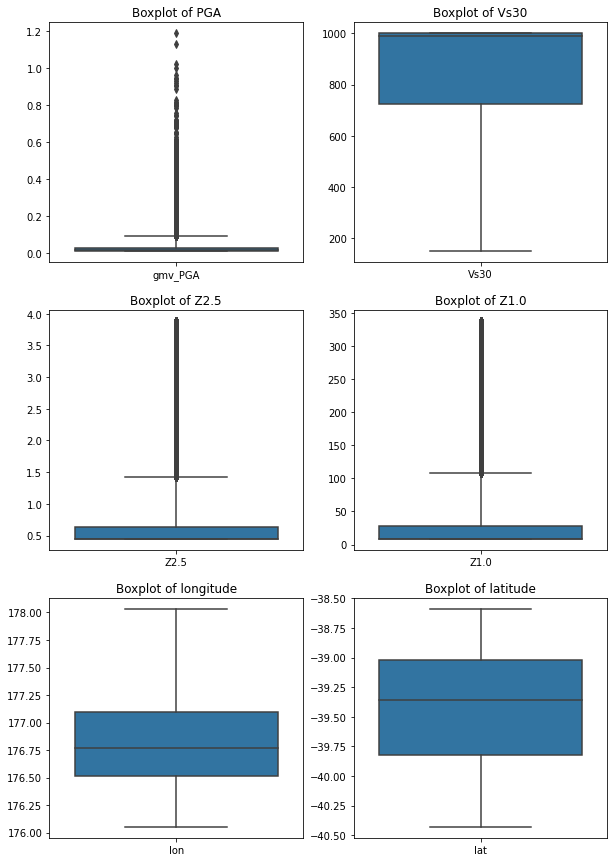

In [ ]:
each_boxplot(HawkesBay_data_full, 4, 'y')

# **3. SUB-DATASET**

## 3.1. Extracting sub-dataset

In [ ]:
# Extracting only small area
# Latitude: -39.70 <= lat <= -39.40
# Longitude: 176.55 <= lon <= 177.90
HawkesBay_data = HawkesBay_data_full[(HawkesBay_data_full['lat']>=-39.70) & 
                                     (HawkesBay_data_full['lat']<=-39.40) & 
                                     (HawkesBay_data_full['lon']>=176.55) & 
                                     (HawkesBay_data_full['lon']<=176.90)]

# Removing 'order' column                                    
HawkesBay_data = HawkesBay_data.drop(columns=["order"])

# Converting site_id format from float to integer
HawkesBay_data.site_id = HawkesBay_data.site_id.astype(int)

In [ ]:
# Dropping off longitude and latitude for modelling then merging later
HawkesBay_data_droplonlat = HawkesBay_data.drop(columns=['lon', 'lat'])

# Checking data
HawkesBay_data_droplonlat.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 145756 entries, 138 to 1927161
Data columns (total 6 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   event_id  145756 non-null  int64  
 1   site_id   145756 non-null  int64  
 2   gmv_PGA   145756 non-null  float64
 3   Vs30      145756 non-null  float64
 4   Z2.5      145756 non-null  float64
 5   Z1.0      145756 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 7.8 MB


## 3.2. General statistical summary for sub-dataset

### 3.2.1. Correlation

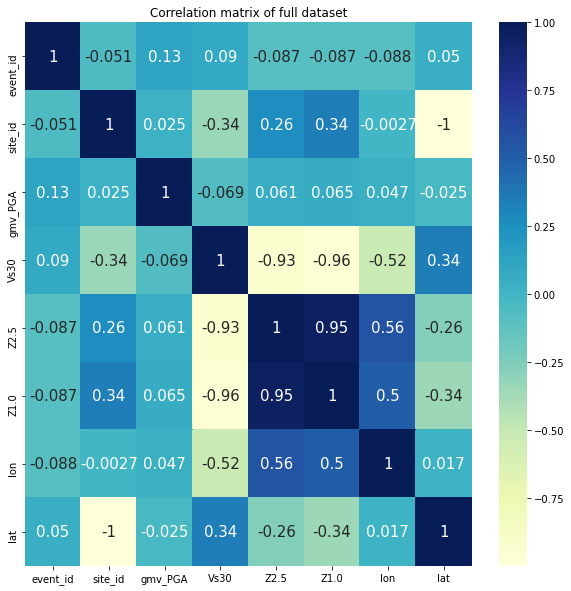

In [ ]:
# Checking correlation
corr_heatmap(HawkesBay_data, 'full dataset')

### 3.2.2. Variances

In [ ]:
# Checking the variances of the small data
HawkesBay_data_droplonlat.var()

event_id     69124.935695
site_id     494605.364514
gmv_PGA          0.000396
Vs30        105073.882663
Z2.5             1.039278
Z1.0         22313.664402
dtype: float64

### 3.2.3. Distributions

Text(0.5, 0.98, 'Distribution of variables in subset dataset')

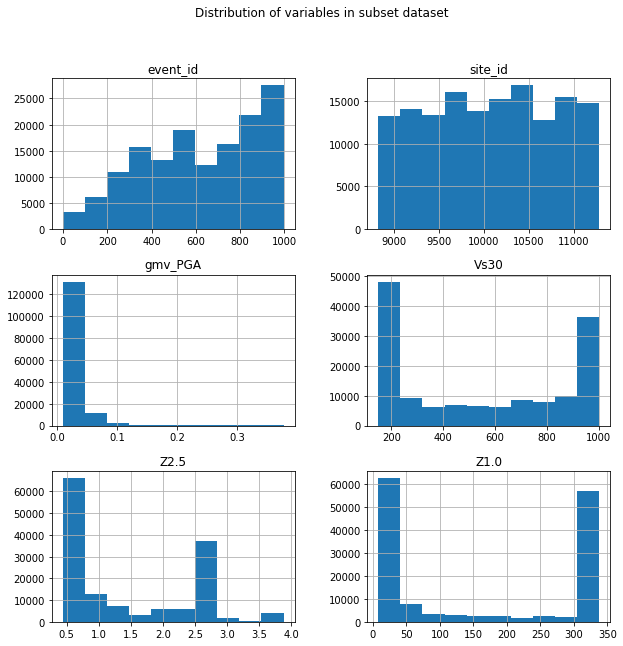

In [ ]:
# Checking the distributions of the small data
HawkesBay_data_droplonlat.hist(figsize=(10, 10))
plt.suptitle('Distribution of variables in subset dataset')

### 3.2.4. Other statistical summary

In [ ]:
# Checking the general statistical summary
HawkesBay_data_droplonlat.describe()

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0
count,145756.000000,145756.000000,145756.000000,145756.000000,145756.000000,145756.000000
mean,621.276318,10076.617731,0.024710,559.461941,1.438027,162.575267
std,262.916214,703.281853,0.019898,324.151018,1.019450,149.377590
min,0.000000,8827.000000,0.010000,150.000000,0.443316,8.266183
25%,402.000000,9484.000000,0.012934,210.000000,0.492182,11.717860
50%,626.000000,10106.000000,0.017909,528.542000,0.919413,91.475169
75%,851.000000,10693.000000,0.028498,912.650000,2.642985,336.092436
max,996.000000,11280.000000,0.377790,1000.000000,3.883874,337.426407


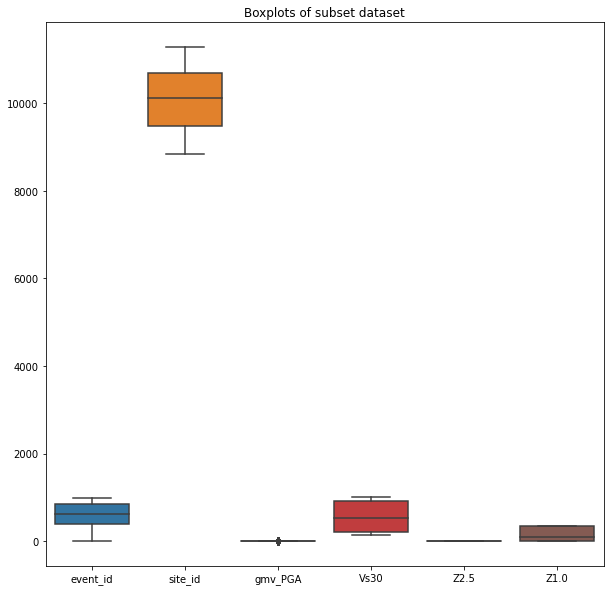

In [ ]:
# Checking the boxplots
full_boxplots(HawkesBay_data_droplonlat, 5, 'subset dataset')

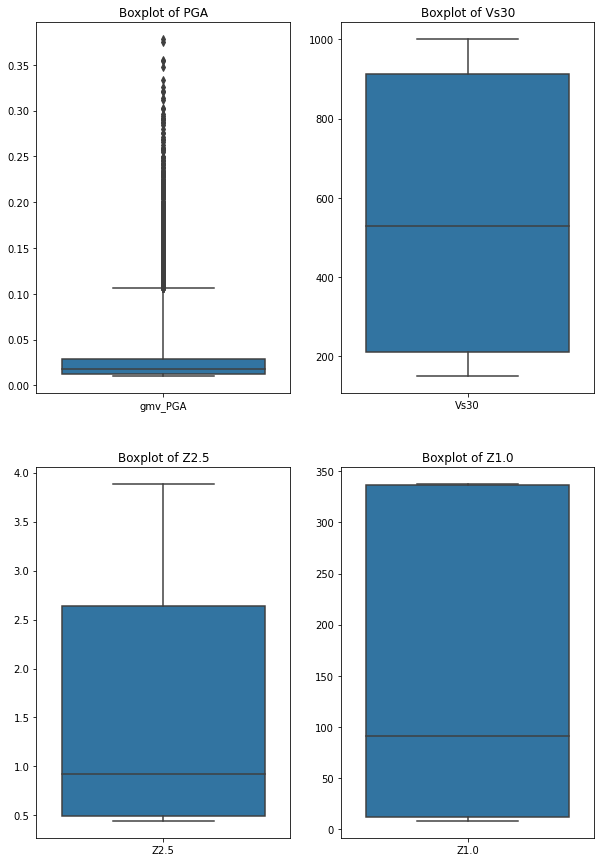

In [ ]:
# Checking boxplots for other variables except event_id and site_id
each_boxplot(HawkesBay_data_droplonlat, 5, 'n')

# **4. CTGAN MODELING**



## 4.1. Splitting data

In [ ]:
# Getting the training sample (20%)
trainingSample = HawkesBay_data_droplonlat.sample(frac=.2)

# Checking data
trainingSample.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 29151 entries, 1581747 to 1298374
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   event_id  29151 non-null  int64  
 1   site_id   29151 non-null  int64  
 2   gmv_PGA   29151 non-null  float64
 3   Vs30      29151 non-null  float64
 4   Z2.5      29151 non-null  float64
 5   Z1.0      29151 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 1.6 MB


In [ ]:
# Importing numpy
import numpy as np

# Transforming PGA
trainingSample['gmv_PGA'] = np.sqrt(np.log(trainingSample['Z1.0']) / trainingSample['gmv_PGA'])

# Checking data
trainingSample.head()

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0
1581747,918,9323,11.415919,1000.000,0.443316,8.266183
35497,75,10891,22.732057,335.965,1.543950,289.039635
1023143,659,10898,16.283543,210.000,2.642985,336.092436
1572446,899,10024,13.276851,926.411,0.483827,11.067282
1889847,987,11079,14.048507,544.397,0.888845,82.247856


## 4.2. Modeling

In [ ]:
# Installing the ctgan package version 0.2.2
!pip install ctgan==0.2.2

  Using cached https://files.pythonhosted.org/packages/bb/4d/9489445b4045979094dc4fe1533834e2607e00f45b04d958f5dcd720c398/ctgan-0.2.2-py2.py3-none-any.whl
ERROR: sdv 0.6.1 has requirement ctgan<0.4,>=0.3.0, but you'll have ctgan 0.2.2 which is incompatible.
  Found existing installation: ctgan 0.3.0
    Uninstalling ctgan-0.3.0:
      Successfully uninstalled ctgan-0.3.0


In [ ]:
# Checking the hyperparameters of CTGANSynthesizer function
from ctgan import CTGANSynthesizer
import inspect
inspect.signature(CTGANSynthesizer)

<Signature (embedding_dim=128, gen_dim=(256, 256), dis_dim=(256, 256), l2scale=1e-06, batch_size=500)>

In [ ]:
# Building up CTGAN model with epoch=200
%%time
ctgan = CTGANSynthesizer(
    embedding_dim=512,
    gen_dim=(512, 256, 64),
    dis_dim=(512, 256, 64),
    l2scale=1e-4, 
    batch_size=3000
)
discrete_columns = ["event_id", 'site_id']
ctgan.fit(trainingSample, discrete_columns,  epochs=200)

Epoch 1, Loss G: 6.6503, Loss D: -0.0345
Epoch 2, Loss G: 6.5305, Loss D: 0.0183
Epoch 3, Loss G: 6.5048, Loss D: 0.0153
Epoch 4, Loss G: 6.5167, Loss D: -0.0098
Epoch 5, Loss G: 6.4755, Loss D: 0.0249
Epoch 6, Loss G: 6.4079, Loss D: 0.0194
Epoch 7, Loss G: 6.4531, Loss D: -0.0557
Epoch 8, Loss G: 6.2930, Loss D: 0.0418
Epoch 9, Loss G: 6.3623, Loss D: -0.0399
Epoch 10, Loss G: 6.3352, Loss D: 0.0012
Epoch 11, Loss G: 6.2906, Loss D: 0.0106
Epoch 12, Loss G: 6.3776, Loss D: -0.0678
Epoch 13, Loss G: 6.1935, Loss D: 0.0375
Epoch 14, Loss G: 6.3362, Loss D: -0.0952
Epoch 15, Loss G: 6.1346, Loss D: 0.0540
Epoch 16, Loss G: 6.2008, Loss D: -0.0612
Epoch 17, Loss G: 6.1068, Loss D: 0.0100
Epoch 18, Loss G: 6.0910, Loss D: -0.0298
Epoch 19, Loss G: 6.0517, Loss D: -0.0367
Epoch 20, Loss G: 5.8838, Loss D: 0.0290
Epoch 21, Loss G: 5.9503, Loss D: -0.1081
Epoch 22, Loss G: 5.7238, Loss D: 0.0143
Epoch 23, Loss G: 5.6051, Loss D: 0.0314
Epoch 24, Loss G: 5.6651, Loss D: -0.0936
Epoch 25, Loss

## 4.3. Saving samples into files

In [ ]:
## Creating sample of 145756 observations
# 140000 - created from looping 14 times of 10000 samples
s = 10000
for v in range(14):
  print(v)
  samples = ctgan.sample(s)
  samples.to_parquet(output_directory / 'CTGAN_output_version30' / f'HawkesBaySyntheticCTGAN{s}samplesVersion{v}.parquet', engine='pyarrow')

# 5756 - created separately
sample_rest = ctgan.sample(5756)
sample_rest.to_parquet(output_directory / 'CTGAN_output_version30' / f'HawkesBaySyntheticCTGAN5756samplesVersion15.parquet', engine='pyarrow')

0
1
2
3
4
5
6
7
8
9
10
11
12
13


# **5. SYNTHETIC DATA**

## 5.1. Gathering data

In [ ]:
# Directory of ctgan samples
pathCTGANoutput = output_directory / 'CTGAN_output_version30'

## Creating a function to combine all ctgan samples
import glob # for looking for all the directories having the given path
import os # for joining the paths
import pandas as pd

# Combining all ctgan samples
def read_and_concatenate_parquets(prefix, path=pathCTGANoutput):
  L = []
  files = glob.glob(os.path.join(path, prefix))
  for file in files:
    print("file loaded : {}".format(file))
    pqt = pd.read_parquet(file)
    L.append(pqt)
  df = pd.concat(L)
  return df

In [ ]:
# Gathering CTGAN samples
ctgan_df_nolonlat = read_and_concatenate_parquets("HawkesBaySyntheticCTGAN*")

file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion0.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion1.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion2.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion3.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion4.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion5.parquet
file loaded : /content/drive/My Drive/Earthquake/for_Martin_and_Jian/CTGAN_output_version30/HawkesBaySyntheticCTGAN10000samplesVersion7.

In [ ]:
# Checking general information of ctgan data without longitude and latitude
# since they were not learnt by the ctgan model
ctgan_df_nolonlat.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 145756 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   event_id  145756 non-null  int64  
 1   site_id   145756 non-null  int64  
 2   gmv_PGA   145756 non-null  float64
 3   Vs30      145756 non-null  float64
 4   Z2.5      145756 non-null  float64
 5   Z1.0      145756 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 7.8 MB


In [ ]:
# Merging the synthetic data with longitude and latitude
geometrical_data = pd.read_csv("OQ/sitemesh_133.csv")
ctgan_df = pd.merge(ctgan_df_nolonlat, 
                    geometrical_data, 
                    on='site_id', 
                    how='left')

## 5.2. General statistical summary for synthetic data

### 5.2.1. Correlation

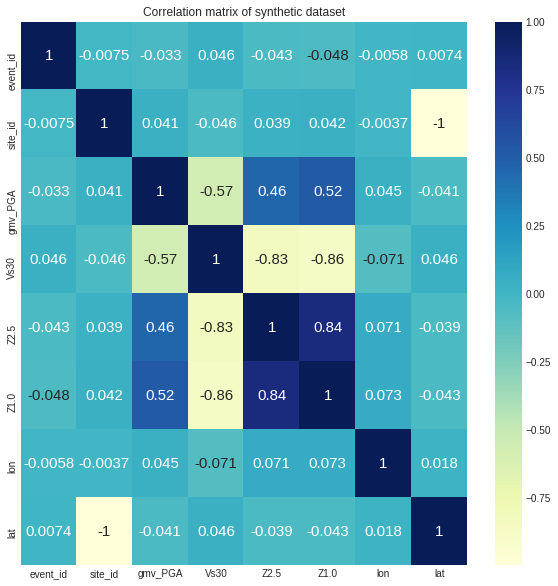

In [ ]:
# Checking correlation
corr_heatmap(ctgan_df, 'synthetic dataset')

### 5.2.2. Variances

In [ ]:
# Checking variances
ctgan_df_nolonlat.var()

event_id     71213.345711
site_id     496452.477091
gmv_PGA         19.953177
Vs30        105452.550132
Z2.5             0.924575
Z1.0         22485.730512
dtype: float64

### 5.2.3. Distributions

Text(0.5, 0.98, 'Distribution of variables in synthetic dataset')

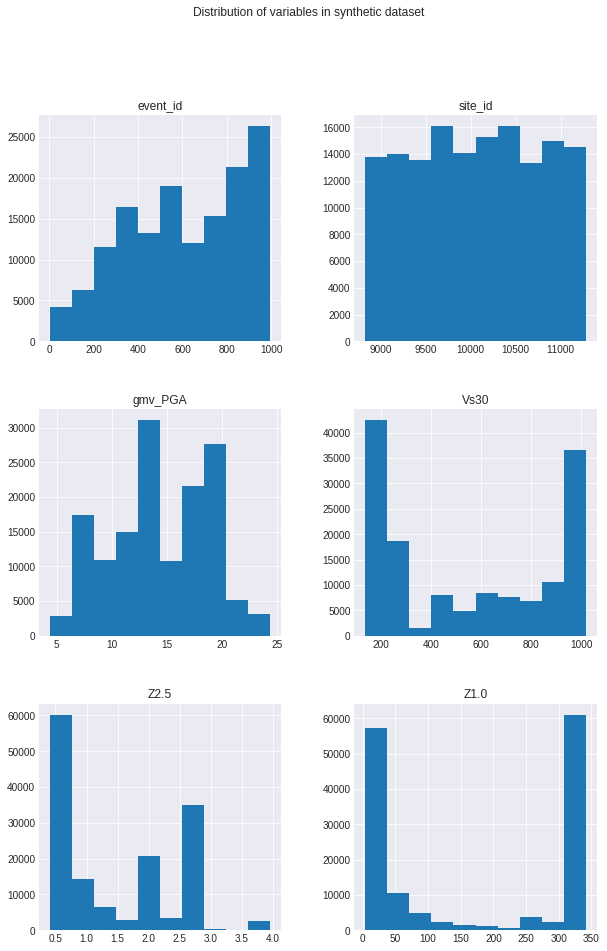

In [ ]:
# Checking distributions
ctgan_df_nolonlat.hist(figsize=(10, 15))
plt.suptitle('Distribution of variables in synthetic dataset')

### 5.2.4. Other statistical summary

In [ ]:
# Checking the descriptive summary
ctgan_df_nolonlat.describe()

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0
count,145756.000000,145756.000000,145756.000000,145756.000000,145756.000000,145756.000000
mean,610.468042,10067.699354,14.378530,566.326355,1.427393,169.042800
std,266.858288,704.593838,4.466898,324.734584,0.961548,149.952427
min,3.000000,8827.000000,4.387995,138.346450,0.410543,3.764132
25%,390.000000,9479.000000,11.414739,218.262534,0.463617,11.245381
50%,606.000000,10099.000000,13.853211,563.145569,1.038958,110.379227
75%,850.000000,10689.000000,18.393933,930.067760,2.620091,335.126467
max,996.000000,11280.000000,24.435736,1017.680800,3.956951,341.323909


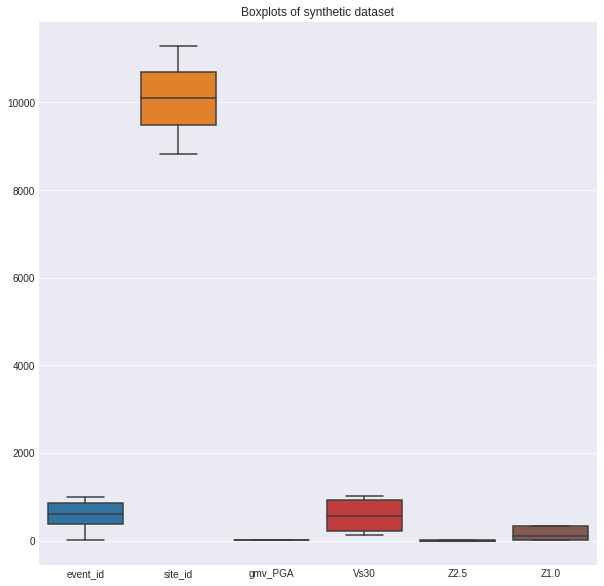

In [ ]:
# Checking boxplots
full_boxplots(ctgan_df_nolonlat, 5, 'synthetic dataset')

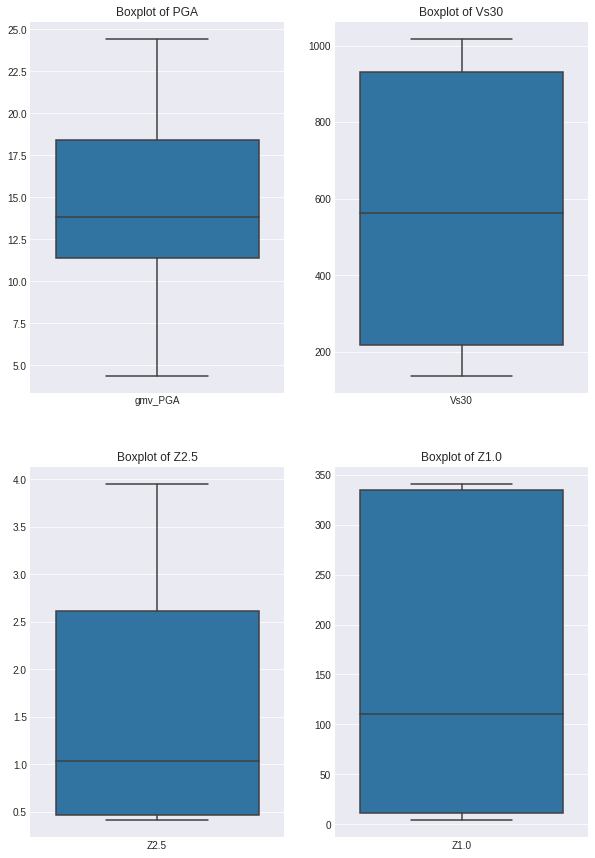

In [ ]:
# Checking boxplots of PGA, Vs30, Z2.5, and Z1.0
each_boxplot(ctgan_df_nolonlat, 5, 'n')

# **6. EVALUATIONS**

## 6.1. Evaluation on whole dataset

In [ ]:
# Installing sdv version 0.6.1
# !pip install sdv==0.6.1
# from sdv.evaluation import evaluate

In [ ]:
# Importing evaluate function one more time as the first time was not successful
from sdv.evaluation import evaluate

In [ ]:
# Evaluating two whole datasets by Logistic Detection
# Both subset and synthetic datasets were used without longitude and latitude
# as these variables were not used in ctgan model
%%time

evaluate(ctgan_df_nolonlat, 
         HawkesBay_data_droplonlat, 
         metrics=['LogisticDetection'], 
         aggregate=False)

CPU times: user 2.43 s, sys: 1.54 s, total: 3.97 s
Wall time: 2.21 s


,metric,name,score,min_value,max_value,goal
0,LogisticDetection,LogisticRegression Detection,0.0,0.0,1.0,MAXIMIZE


In [ ]:
# Creating copies for both subset and synthetic data to evaluate specifically for site_id only
real_copy = HawkesBay_data.copy(deep=True)
ctgan_copy = ctgan_df.copy(deep=True)

## 6.2. Evaluations on all variables by Cosine Similarity method

In [ ]:
# Creating function to do cosine similarity calculation
# This function would be used for site_id and event_id

def calculate_cosine_similarity(column_calculated):
  ''' This function is to calculate cosine similarity of two variables
  Sources: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html#sklearn.metrics.pairwise.cosine_similarity
           https://gist.github.com/pgolding/fdf74a3e8e797fad0391befd5a906ddb
  Arguments:
            column_calculated:
                      The name of the column/variable need calculating cosine similarity.
  '''                    

  # Creating dataframes for both subset and synthetic data 
  # Each dataframe contains only one column
  real_dataframe = pd.DataFrame({column_calculated: real_copy[column_calculated]})
  ctgan_dataframe = pd.DataFrame({column_calculated: ctgan_copy[column_calculated]})

  # Converting into numpy array
  real_array = real_dataframe.to_numpy()
  ctgan_array = ctgan_dataframe.to_numpy()

  # Reshaping arrays
  real_array = real_array.reshape(1, -1)
  ctgan_array = ctgan_array.reshape(1, -1)

  # Calculating cosine similarity
  from sklearn.metrics.pairwise import cosine_similarity
  result = cosine_similarity(real_array, ctgan_array)
  return result

In [ ]:
# Evaluating similarity of variables
# Creating variables containing all columns' names
var_name = real_copy.drop(columns=['lon', 'lat']).columns.to_list()

# Calculating cosine similarity
for name in var_name:
  result = calculate_cosine_similarity(name)[0][0]
  print('Cosine similarity score of {} is: {:.5f}'.format(name, result))

Cosine similarity score of event_id is: 0.84336
Cosine similarity score of site_id is: 0.99515
Cosine similarity score of gmv_PGA is: 0.74286
Cosine similarity score of Vs30 is: 0.75045
Cosine similarity score of Z2.5 is: 0.67691
Cosine similarity score of Z1.0 is: 0.55075


## 6.3. Evaluations on all variables by Correlation method

In [ ]:
# Although matplotlib and seaborn were installed, we still install them again with newer versions
!pip install matplotlib
!pip install seaborn==0.11.1

In [ ]:
# Function 1
# Creating a function to calculate Pearson's and Spearman's correlations
# This function would be used for all correlation calculation in this project

%matplotlib inline
plt.style.use('seaborn-whitegrid')
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

def calculate_correlation(real_df, 
                          ctgan_df, 
                          column_merge, 
                          column_correlated,
                          newname_column_correlated):
  ''' The function is used to calculate the correlation similarity - both Pearson and Spearman style
  For more details please visit: https://towardsdatascience.com/calculate-similarity-the-most-relevant-metrics-in-a-nutshell-9a43564f533e
  Arguments:
            real_df:
                Dataframe created from subset data.
            ctgan_df:
                Dataframe created from synthetic data.
            column_merge:
                Column in both dataframes used to merge.
            column_correlated:
                Current name of columns would be used to calculate correlations.
            newname_column_correlated:
                New name for columns used to calculate correlations.
  '''

  # Preparing data
  dfCorrelation = real_df
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_real_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = pd.merge(dfCorrelation, ctgan_df, how='outer', on=column_merge)
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_ctgan_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = dfCorrelation.fillna(0)

  # Calculating Pearson's correlation
  corrp, _ = stats.pearsonr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                            dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)

  # Calculating Spearman's correlation
  corrs, _ = stats.spearmanr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                             dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)

  return corrp, corrs

In [ ]:
# Function 2
# Creating a function to plot the correlations of both styles - Pearson and Spearman
# This function would be used for all correlation calculation in this project

%matplotlib inline
plt.style.use('seaborn-whitegrid')
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

def plot_correlation(real_df, 
                     ctgan_df, 
                     column_merge,
                     column_correlated,
                     newname_column_correlated):
  ''' The function is used to plot the correlation similarity - both Pearson and Spearman styles
  For more details please visit: https://towardsdatascience.com/calculate-similarity-the-most-relevant-metrics-in-a-nutshell-9a43564f533e
  Arguments:
            real_df:
                Dataframe created from subset data.
            ctgan_df:
                Dataframe created from synthetic data.
            column_merge:
                Column in both dataframes used to merge.
            column_correlated:
                Current name of columns would be used to calculate correlations.
            newname_column_correlated:
                New name for columns used to calculate correlations.
  '''

  # Preparing data
  dfCorrelation = real_df
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_real_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = pd.merge(dfCorrelation, ctgan_df, how='outer', on=column_merge)
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_ctgan_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = dfCorrelation.fillna(0)

  # Calculating Pearson's correlation
  corrp, _ = stats.pearsonr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                            dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)
  print("Pearson's correlation: %.3f" % corrp)

  # Calculating Spearman's correlation
  corrs, _ = stats.spearmanr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                             dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)
  print("Spearman's correlation: %.3f" % corrs)

  # Plotting
  plt.style.use('seaborn-whitegrid')
  fig, ax = plt.subplots(figsize=(10, 10))
  pl = sns.regplot(x=f'HawkesBay_ctgan_{newname_column_correlated}', 
                   y=f'HawkesBay_real_{newname_column_correlated}', 
                   data=dfCorrelation, fit_reg=True, 
                   color='black', marker='+', ax=ax)
  pl.set_title(f"Correlation of {newname_column_correlated}")
  plt.show()

### 6.3.1. Evaluations on frequencies of discrete variables by Correlation method

In [ ]:
# Creating a list of discrete variables
discrete_var = var_name[:2][::-1]

# Creating a list of continuous variables
continuous_var = var_name[2:]

In [ ]:
# Creating a function to count the frequency of each unique site_id/event_id
def count_fid_occurences(df, column):
  '''The function is used to count the frequency of a given column from a dataframe
  Arguments:
            df:
              Dataframe contains the column.
            column:
              The column needs counting.
  '''
  count = df[column].value_counts()
  count_df = pd.DataFrame({column: count.index, 'count': count.values})
  count_df["count"] = pd.to_numeric(count_df["count"])
  return count_df

In [ ]:
# Checking the number of rows by site_id after counting the frequency
# To see if the ctgan model could learn the quantity of unique site_id.
# If the result equals to 0, the model learnt well
len(count_fid_occurences(real_copy, 'site_id')) - len(count_fid_occurences(ctgan_copy, 'site_id'))

0

In [ ]:
# Checking the number of rows by event_id after counting the frequency
# To see if the ctgan model could learn the quantity of unique event_id.
# If the result equals to 0, the model learnt well
len(count_fid_occurences(real_copy, 'event_id')) - len(count_fid_occurences(ctgan_copy, 'event_id'))

49

In [ ]:
# Creating a function to create a table of correlations for variables
# This function would be used for all correlations in this project 

def corr_df(list_variable_name, type_var):
  ''' This function is to create a dataframe showing Pearson's and Spearman's correlations
      for all variables
  For more details please visit: https://datatofish.com/create-pandas-dataframe/
  Arguments:
            list_variable_name:
                List of names of selected variables in a datasets
            type_var:
                Type of variables - discrete or continuous (d or c)
  '''
  # Creating two lists containing correlations scores for variables
  p_result = []
  s_result = []

  # Calculating correlations for discrete variables
  if type_var == 'd':
    for var in list_variable_name:
      corr_p, corr_s = calculate_correlation(count_fid_occurences(real_copy, var),
                                             count_fid_occurences(ctgan_copy, var),
                                             var, 'count', 'correlation')
      p_result.append(corr_p)
      s_result.append(corr_s)
  # Calculating correlations for continuous variables
  else:
    for var in list_variable_name:
      corr_p, corr_s = calculate_correlation(continuous_var_df(real_mean, var),   # This function would be created later
                                             continuous_var_df(ctgan_mean, var),  # This function would be created later
                                             'site_id', var, 'averaged_'+var)
      p_result.append(corr_p)
      s_result.append(corr_s)

  # Creating a table of correlations for variables
  corr_dict = {'Variables': list_variable_name,
               "Pearson's Correlation": p_result,
               "Spearman's Correlation": s_result}

  corr_df = pd.DataFrame(corr_dict,
                         columns=['Variables', 
                                  "Pearson's Correlation",
                                  "Spearman's Correlation"])

  return corr_df

In [ ]:
# Creating a table of correlations of discrete variables
corr_df(discrete_var, 'd')

,Variables,Pearson's Correlation,Spearman's Correlation
0,site_id,0.722813,0.735938
1,event_id,0.973573,0.979932


In [ ]:
# Creating a function to call out plots of correlations of variables
# This function would be used for all of correlation plotting in this project

def corr_plot(list_variable_name, type_var):
  ''' This function is to create a dataframe showing Pearson's and Spearman's correlations
      for all variables
  Arguments:
            list_variable_name:
                List of names of selected variables in a datasets
            type_var:
                Type of variables - discrete or continuous (d or c)
  '''
  # Plotting for discrete variables
  if type_var == 'd':
    for var in list_variable_name:
      print()
      print("-"*35 + " " + var + " " + "-"*35)
      plot_correlation(count_fid_occurences(real_copy, var),
                       count_fid_occurences(ctgan_copy, var),
                       var, 'count', var+'_count')
  # Plotting for continuous variables
  else:
    for var in list_variable_name:
      print()
      print("-"*35 + " " + var + " " + "-"*35)
      plot_correlation(continuous_var_df(real_mean, var),   # This function would be created later
                       continuous_var_df(ctgan_mean, var),  # This function would be created later
                       'site_id', var, 'averaged_'+var)
    


----------------------------------- site_id -----------------------------------
Pearson's correlation: 0.723
Spearman's correlation: 0.736


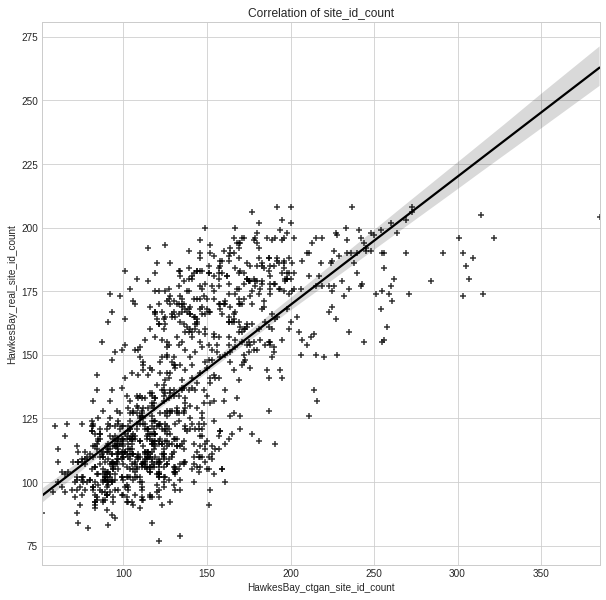


----------------------------------- event_id -----------------------------------
Pearson's correlation: 0.974
Spearman's correlation: 0.980


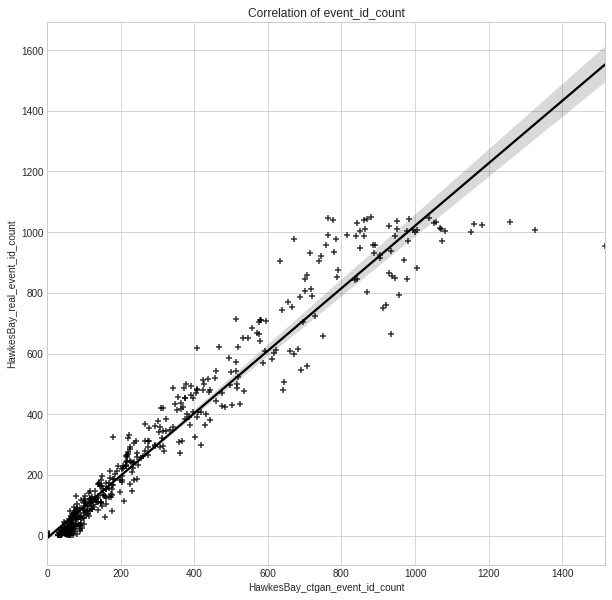

In [ ]:
# Plotting correlations for discrete variables
corr_plot(discrete_var, 'd')

### 6.3.2. Evaluations on values of continuous variables by Correlation method

In [ ]:
# Creating a function to create an averaged dataset
def averaged_dataset(df):
  ''' This function is to average dataframe containing longitude and latitude, 
      specifically real data and ctgan data in this project
  Arguments:
            df:
              Dataframe needs averaging
  '''
  # Averaging dataset without longitude and latitude
  df_mean = df.drop(columns=['lon', 'lat']).groupby('site_id').mean()

  # Merging with sitemesh_133.csv file to get longitude and latitude
  df_mean_lonlat = pd.merge(df_mean, geometrical_data, on='site_id')

  return df_mean_lonlat

In [ ]:
# Applying averaging function to both real and ctgan dataframes
real_mean = averaged_dataset(real_copy)
ctgan_mean = averaged_dataset(ctgan_copy)

In [ ]:
# Checking data information
real_mean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1050 entries, 0 to 1049
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   site_id   1050 non-null   int64  
 1   event_id  1050 non-null   float64
 2   gmv_PGA   1050 non-null   float64
 3   Vs30      1050 non-null   float64
 4   Z2.5      1050 non-null   float64
 5   Z1.0      1050 non-null   float64
 6   lon       1050 non-null   float64
 7   lat       1050 non-null   float64
dtypes: float64(7), int64(1)
memory usage: 73.8 KB


In [ ]:
# Checking data information
ctgan_mean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1050 entries, 0 to 1049
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   site_id   1050 non-null   int64  
 1   event_id  1050 non-null   float64
 2   gmv_PGA   1050 non-null   float64
 3   Vs30      1050 non-null   float64
 4   Z2.5      1050 non-null   float64
 5   Z1.0      1050 non-null   float64
 6   lon       1050 non-null   float64
 7   lat       1050 non-null   float64
dtypes: float64(7), int64(1)
memory usage: 73.8 KB


In [ ]:
# Creating a function to create a small dataframe including a continuous variable and site_id
def continuous_var_df(df, column):
  '''This function is to create a small dataframe including two columns - 
     site_id and a continuous variable
  Arguments:
            df:
              Dataframe contains the site_id and the continuous variable
            column:
              Column's name
  '''
  con_var_df = pd.DataFrame({'site_id': df.site_id,
                             column: df[column]})
  return con_var_df


----------------------------------- gmv_PGA -----------------------------------
Pearson's correlation: 0.344
Spearman's correlation: 0.378


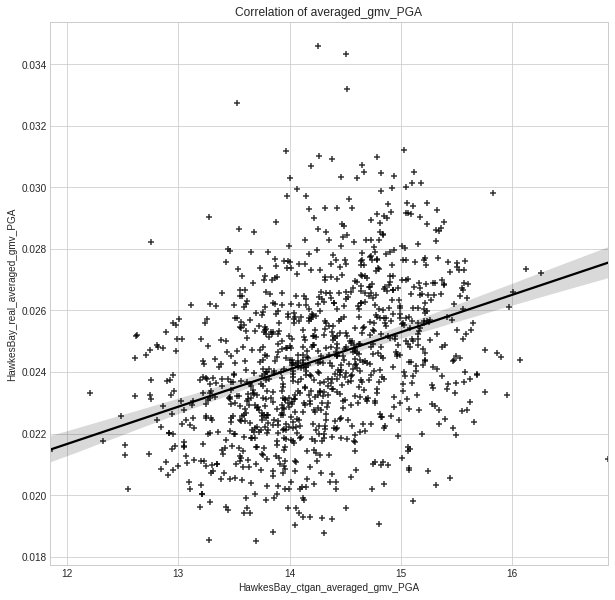


----------------------------------- Vs30 -----------------------------------
Pearson's correlation: 0.703
Spearman's correlation: 0.692


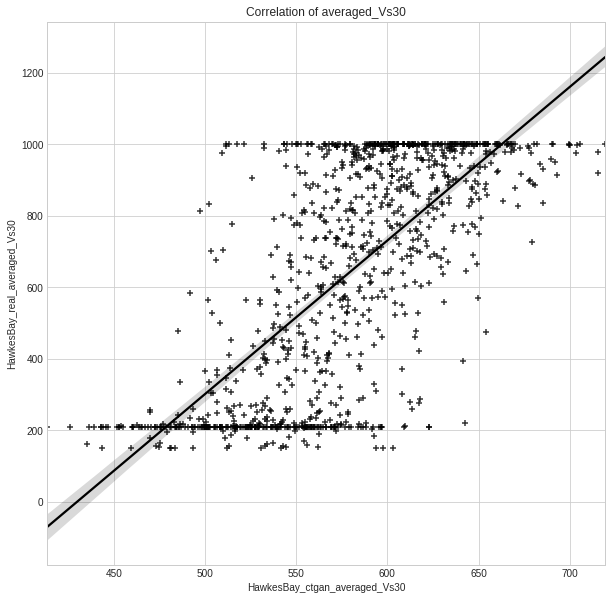


----------------------------------- Z2.5 -----------------------------------
Pearson's correlation: 0.670
Spearman's correlation: 0.630


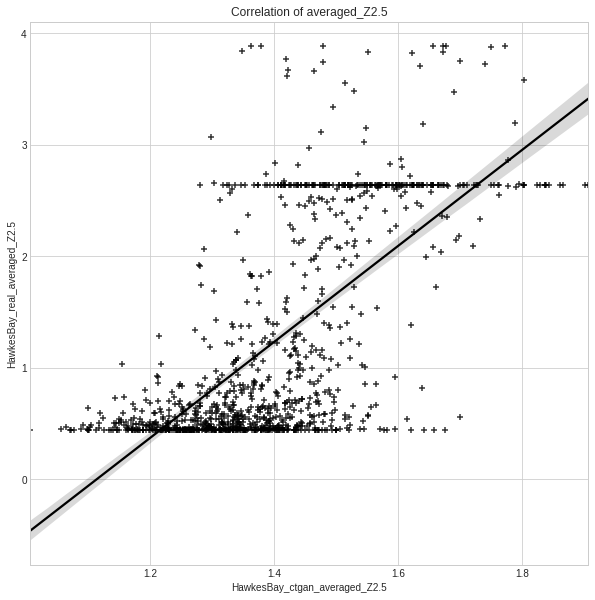


----------------------------------- Z1.0 -----------------------------------
Pearson's correlation: 0.696
Spearman's correlation: 0.679


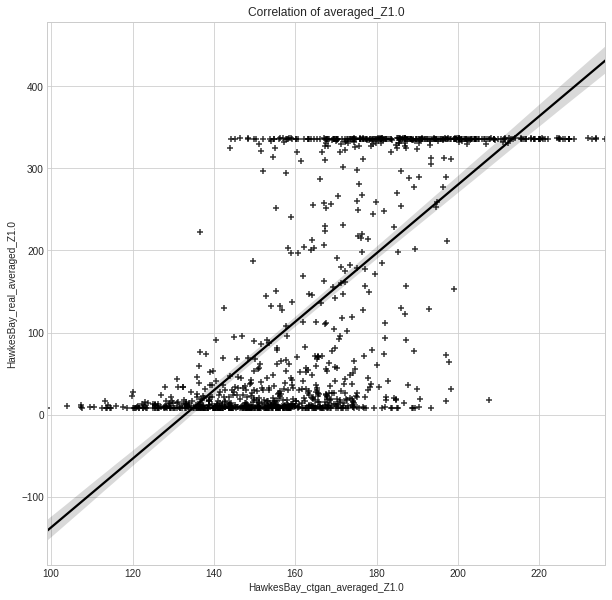

In [ ]:
# Plotting correlations for continuous data
corr_plot(continuous_var, 'c')

In [ ]:
# Creating a table of correlations of continuous variables
corr_df(continuous_var, 'c')

,Variables,Pearson's Correlation,Spearman's Correlation
0,gmv_PGA,0.343741,0.378207
1,Vs30,0.703214,0.692289
2,Z2.5,0.669882,0.629751
3,Z1.0,0.695649,0.678942


## 6.4. Evaluations on patterns of continuous variables by Mapping method

In [ ]:
# Installing geopandas
!pip install geopandas

In [ ]:
# Creating a function to convert the pandas dataframes 
# into geopandas dataframe for mapping. This function also does
# MinMax and Quantile scaling for a specific variable

# Importing preprocessing from scikit-learn for using scaling functions
from sklearn import preprocessing

# Importing geopandas
import geopandas as gpd

def gdf_minmax_quantile(variable):
  '''This function is to convert the pandas dataframes into geopandas dataframes for mapping.
     It also includes doing scaling with MinMax and Quantile styles for a specific variable.
  For more details please visit: https://geopandas.org/gallery/create_geopandas_from_pandas.html
                                 https://stackoverflow.com/questions/63644131/how-to-use-geopandas-to-plot-latitude-and-longitude-on-a-more-detailed-map-with
  Arguments:
            variable:
                The variable needs mapping
  '''
  # Creating two more copies from the real and ctgan dataframes
  # to avoid the impacts from the further process
  real_mean_copy = real_mean.copy(deep=True)
  ctgan_mean_copy = ctgan_mean.copy(deep=True)

  # Converting pandas dataframes into geopandas dataframes
  gdf_real = gpd.GeoDataFrame(real_mean_copy,
                              geometry = gpd.points_from_xy(real_mean_copy.lon, 
                                                           real_mean_copy.lat))
  gdf_ctgan = gpd.GeoDataFrame(ctgan_mean_copy,
                               geometry = gpd.points_from_xy(ctgan_mean_copy.lon, 
                                                           ctgan_mean_copy.lat))
  
  # Scaling data
  # Calling out scaling functions
  min_max_scaler = preprocessing.MinMaxScaler()
  quantile_scaler = preprocessing.QuantileTransformer()

  # MinMax scaling
  gdf_real['MinMax'] = min_max_scaler.fit_transform(gdf_real[[variable]].values.astype(float))
  gdf_ctgan['MinMax'] = min_max_scaler.fit_transform(gdf_ctgan[[variable]].values.astype(float))
  
  # Quantile scaling
  gdf_real['Quantile'] = quantile_scaler.fit_transform(gdf_real[[variable]].values.astype(float))
  gdf_ctgan['Quantile'] = quantile_scaler.fit_transform(gdf_ctgan[[variable]].values.astype(float))

  return gdf_real, gdf_ctgan

In [ ]:
# Creating a function to plot the distributions of the pair - real and ctgan data 
# for averaged, MinMax scaling, Quantile scaling versions

def dis_plot(variable):
  '''This function is to plot the real data and ctgan data distributions
     when averaging, MinMax scaling, and Quantile scaling
  For more details please visit: https://dev.to/thalesbruno/subplotting-with-matplotlib-and-seaborn-5ei8
  Arguments:
          variable:
              The variable needs mapping
  '''
  fig, axes = plt.subplots(2, 3, figsize=(20, 15))
  fig.suptitle(f'Distributions of {variable} of real and ctgan data when averaging, MinMax scaling, and Quantile scaling')

  # Converting pandas dataframes into geopandas dataframes
  # and scaling
  gdf_real_var, gdf_ctgan_var = gdf_minmax_quantile(variable)

  # Real data - Distributions when averaging, MinMax scaling, and Quantile scaling
  sns.distplot(gdf_real_var[variable], kde=True, ax=axes[0, 0]).set_title('Real data distributions - Average')
  sns.distplot(gdf_real_var.MinMax, kde=True, ax=axes[0, 1]).set_title('Real data distributions - MinMax Scaling')
  sns.distplot(gdf_real_var.Quantile, kde=True, ax=axes[0, 2]).set_title('Real data distributions - Quantile Scaling')

  # Ctgan data - Distributions when averaging, MinMax scaling, and Quantile scaling
  sns.distplot(gdf_ctgan_var[variable], kde=True, color='y', ax=axes[1, 0]).set_title('Ctgan data distributions - Average')
  sns.distplot(gdf_ctgan_var.MinMax, kde=True, color='y', ax=axes[1, 1]).set_title('Ctgan distributions - MinMax Scaling')
  sns.distplot(gdf_ctgan_var.Quantile, kde=True, color='y', ax=axes[1, 2]).set_title('Ctgan data distributions - Quantile Scaling')

In [ ]:
# Creating a function to map the underlying features of continuous data based on the site_id

# Importing wrap function
from textwrap import wrap

def mapping(variable):
  '''This function is to map the patterns in the real data and ctgan data
     when averaging, MinMax scaling, and Quantile scaling
  For more details please visit: https://dev.to/thalesbruno/subplotting-with-matplotlib-and-seaborn-5ei8
  Arguments:
          variable:
              The variable needs mapping
  '''
  plt.style.use('seaborn-darkgrid')
  fig, ((ax1, ax2), (ax1b, ax2b), (ax1c, ax2c)) = plt.subplots(nrows=3, ncols=2, 
                                                               figsize=(15, 15))
  # Converting pandas dataframes into geopandas dataframes
  # and scaling
  gdf_real_var, gdf_ctgan_var = gdf_minmax_quantile(variable)

  # Averaging
  gdf_real_var.plot(ax=ax1, column=variable, cmap='YlOrRd', legend=True)
  gdf_ctgan_var.plot(ax=ax2, column=variable, cmap='YlOrRd', legend=True)
  ax1.set_title("\n".join(wrap('Averaged - Shaking events in Hawkes Bay - Real data ~ 1 millions observations', 35)))
  ax1.ticklabel_format(useOffset=False, style='plain')
  ax2.set_title("\n".join(wrap('Averaged - Shaking events in Hawkes Bay - CTGAN data ~ 20% observations training set', 35)))
  ax2.ticklabel_format(useOffset=False, style='plain')

  # MinMax scaling 
  gdf_real_var.plot(ax=ax1b, column='MinMax', cmap='YlOrRd', legend=True)
  gdf_ctgan_var.plot(ax=ax2b, column='MinMax', cmap='YlOrRd', legend=True)
  ax1b.set_title("\n".join(wrap('MinMax Scaling - Shaking events in Hawkes Bay - Real data ~ 1 millions observations', 35)))
  ax1b.ticklabel_format(useOffset=False, style='plain')
  ax2b.set_title("\n".join(wrap('MinMax Scaling - Shaking events in Hawkes Bay - CTGAN data ~ CTGAN data ~ 20% observations training set', 35)))
  ax2b.ticklabel_format(useOffset=False, style='plain')

  # Quantile scaling
  gdf_real_var.plot(ax=ax1c, column='Quantile', cmap='YlOrRd', legend=True)
  gdf_ctgan_var.plot(ax=ax2c, column='Quantile', cmap='YlOrRd', legend=True)
  ax1c.set_title("\n".join(wrap('Quantile Scaling - Shaking events in Hawkes Bay - Real data ~ 1 millions observations', 35)))
  ax1c.ticklabel_format(useOffset=False, style='plain')
  ax2c.set_title("\n".join(wrap('Quantile Scaling - Shaking events in Hawkes Bay - CTGAN data ~ 20% observations training set', 35)))
  ax2c.ticklabel_format(useOffset=False, style='plain')

  fig.autofmt_xdate()
  plt.tight_layout()
  plt.show()


### 6.4.1. Mapping PGA

/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function 

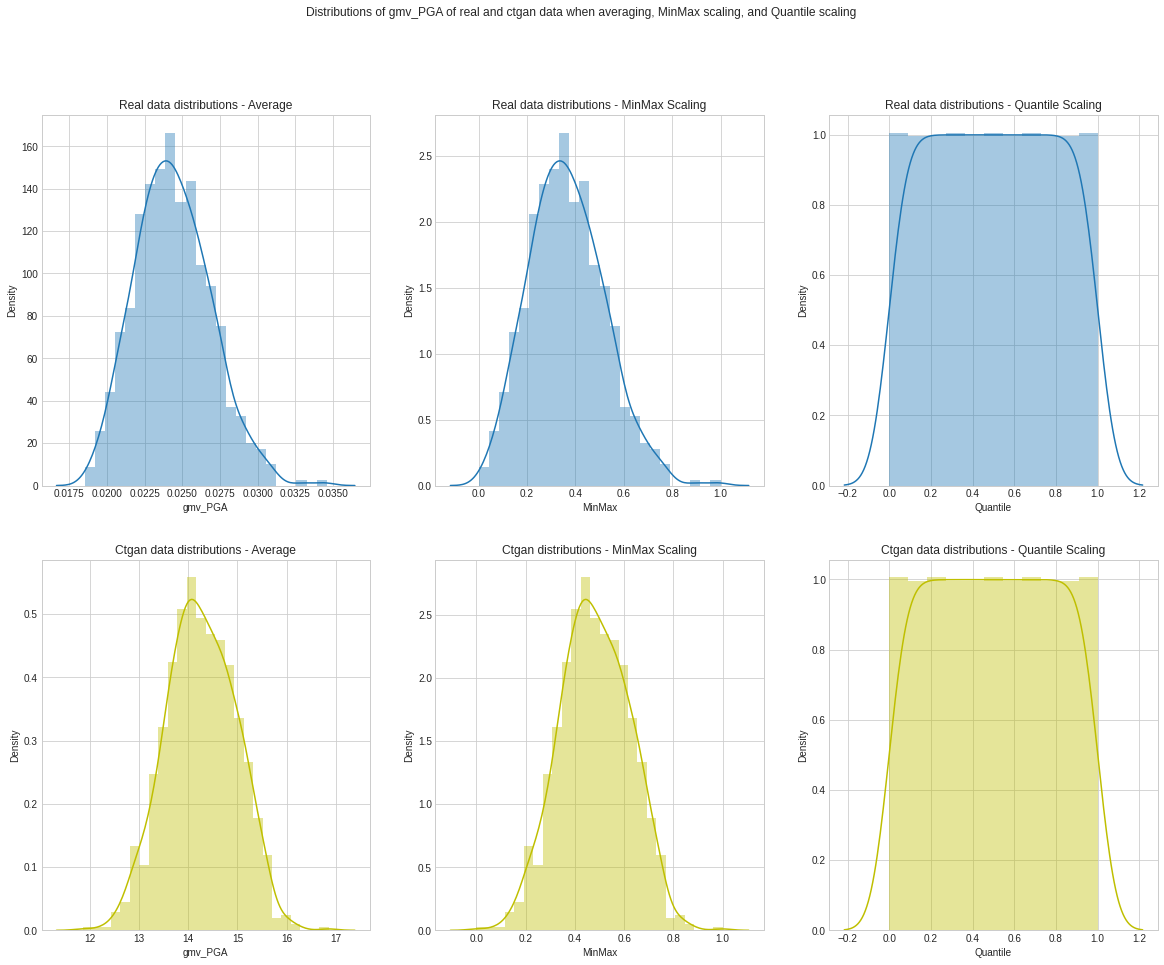

In [ ]:
# Plotting the distributions of PGA
dis_plot('gmv_PGA')

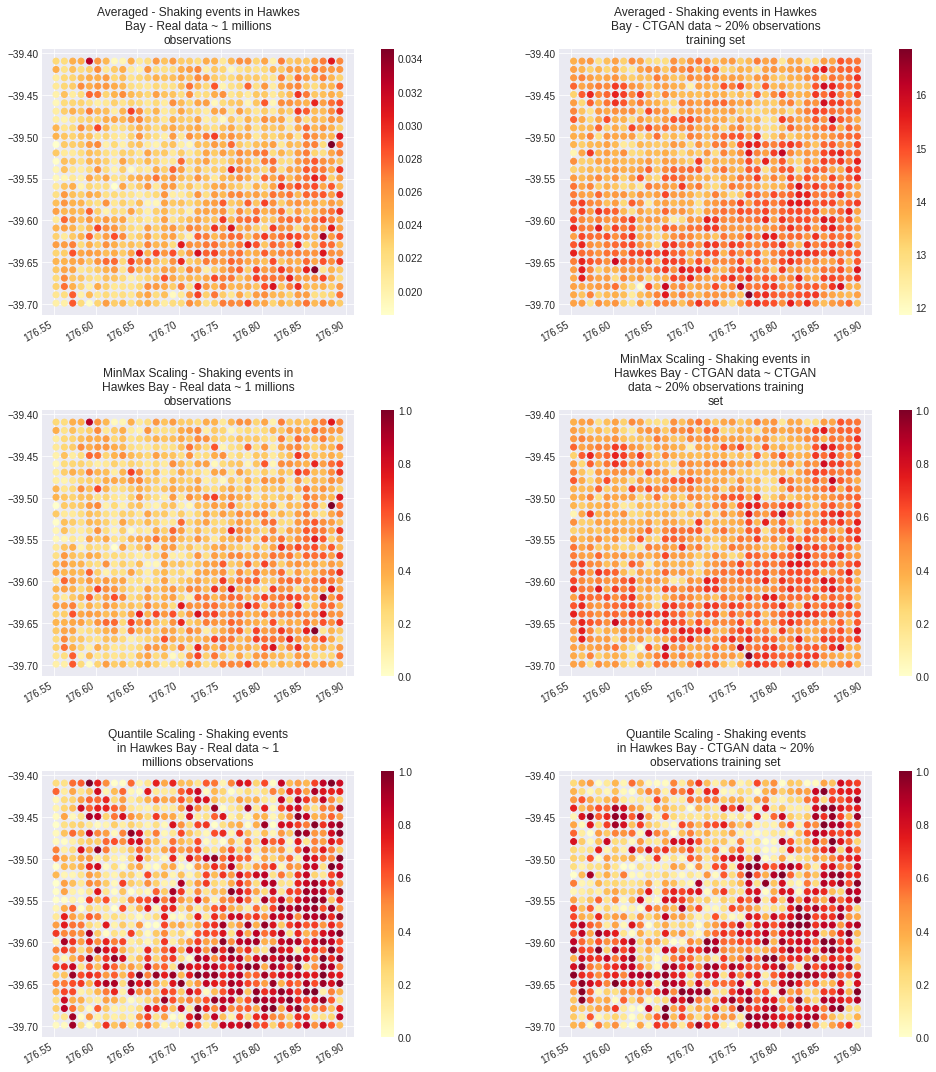

In [ ]:
# Mapping the patterns of PGA
mapping('gmv_PGA')

### 6.4.2. Mapping Vs30

/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function 

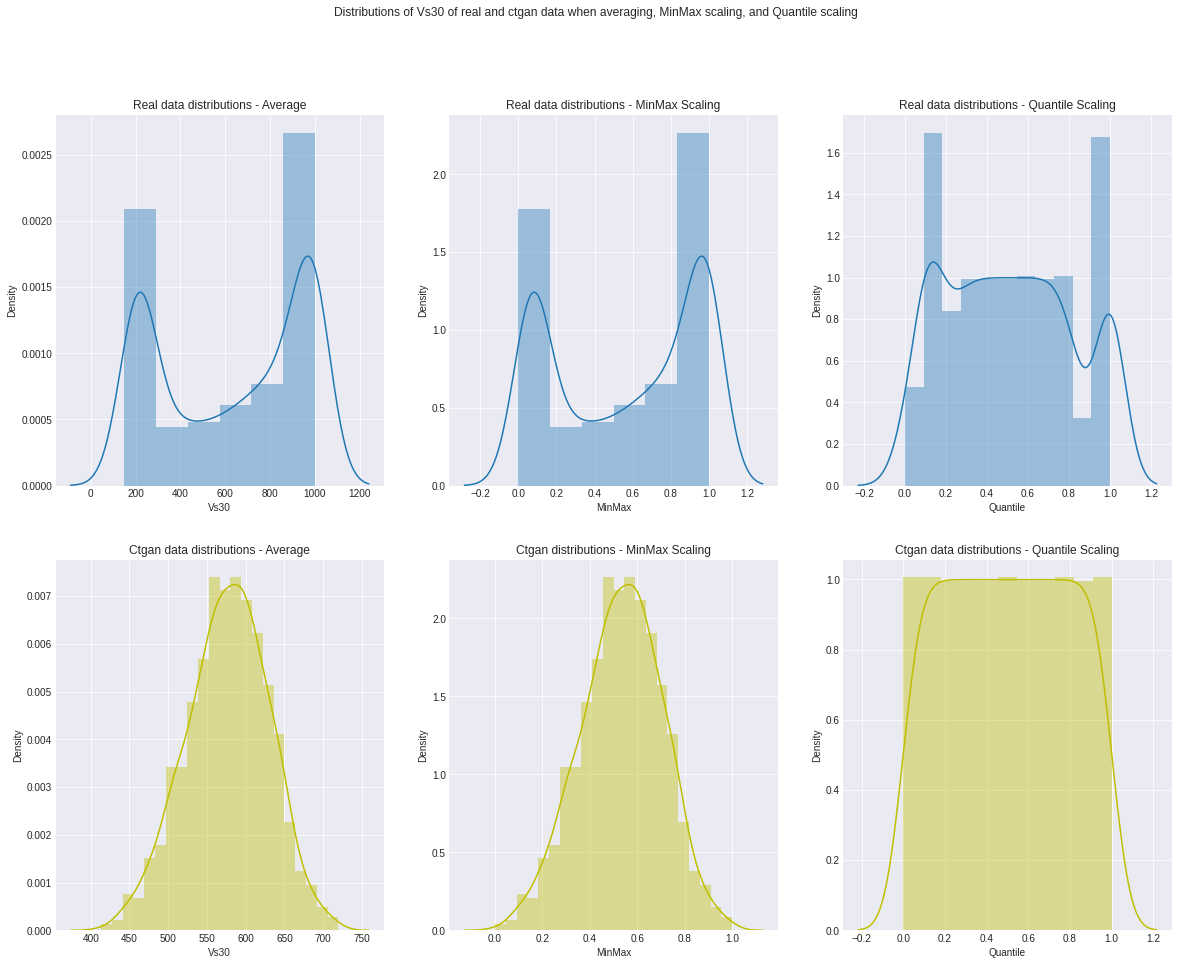

In [ ]:
# Plotting the distributions of PGA
dis_plot('Vs30')

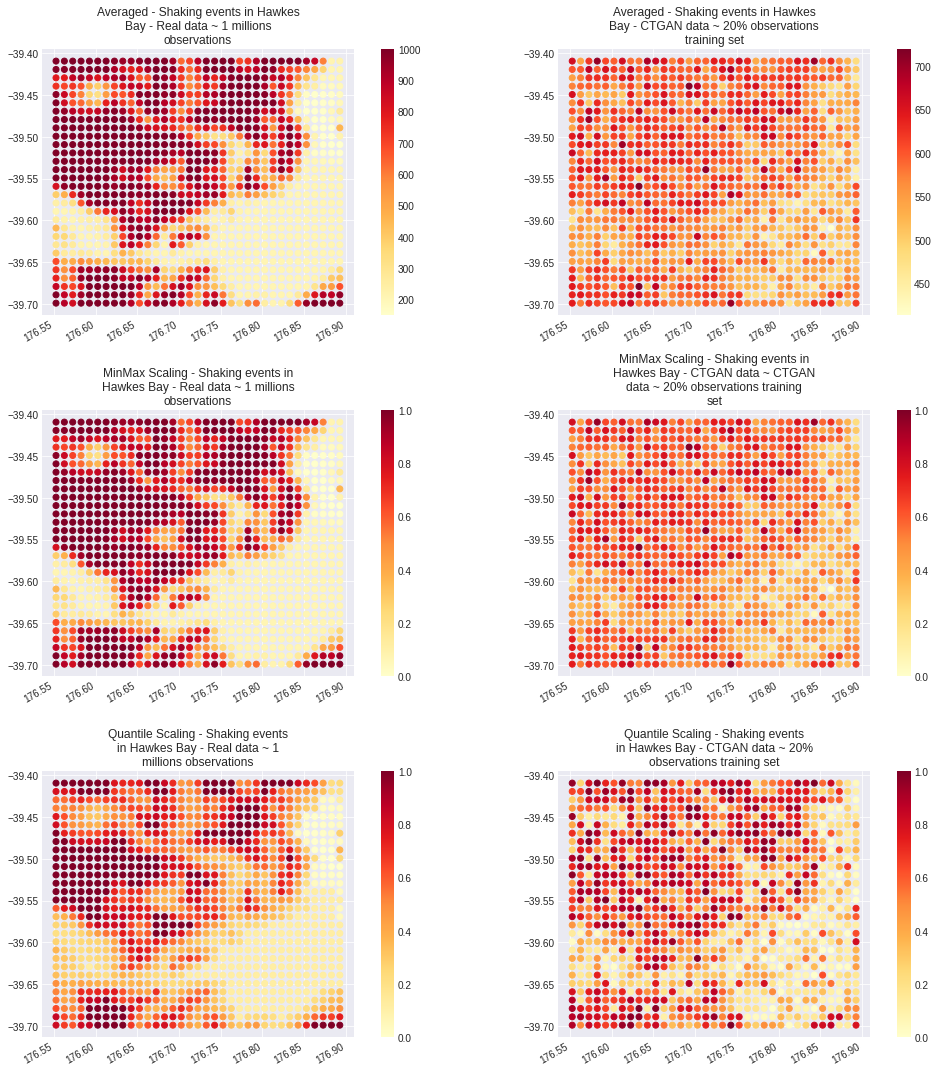

In [ ]:
# Mapping the patterns of PGA
mapping('Vs30')

### 6.4.3. Mapping Z2.5

/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function 

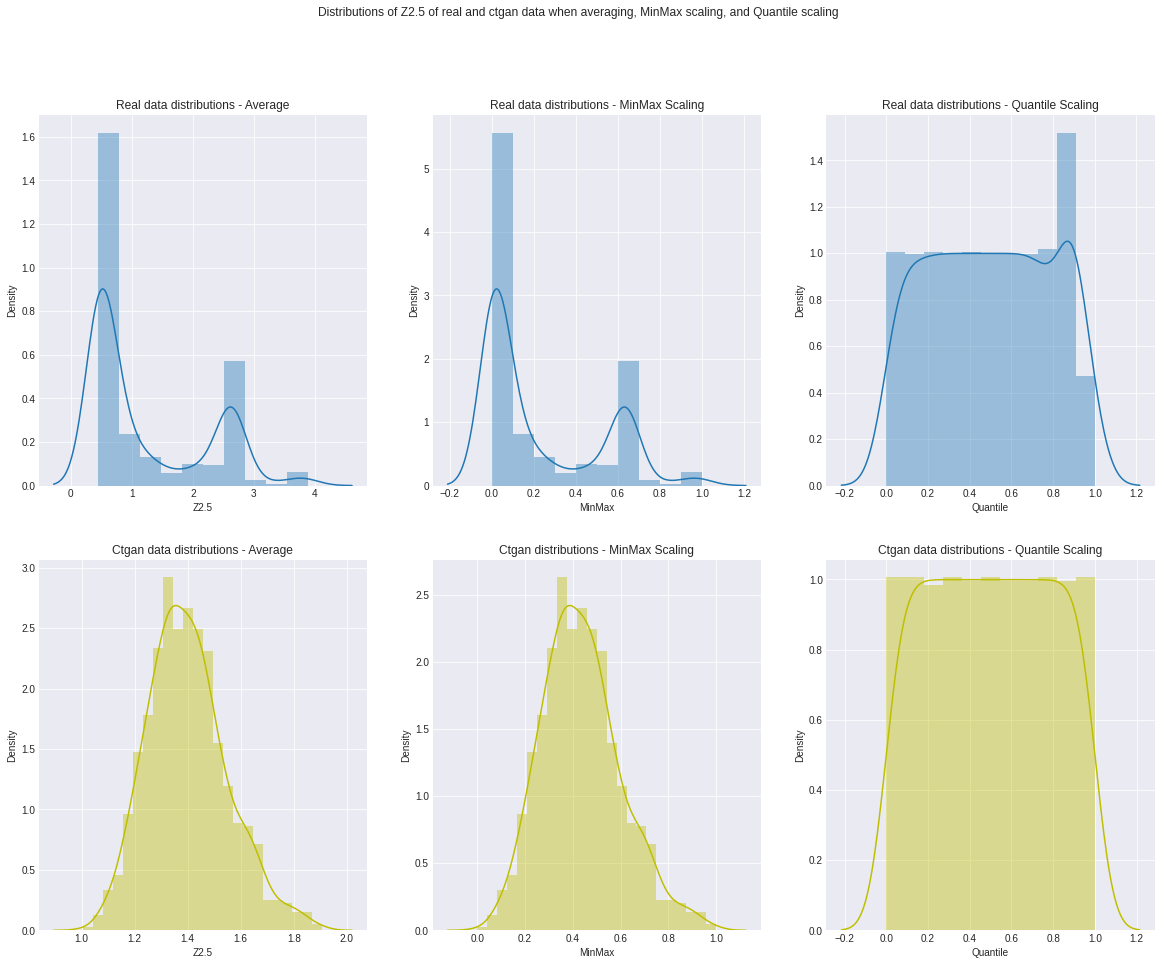

In [ ]:
# Plotting the distributions of PGA
dis_plot('Z2.5')

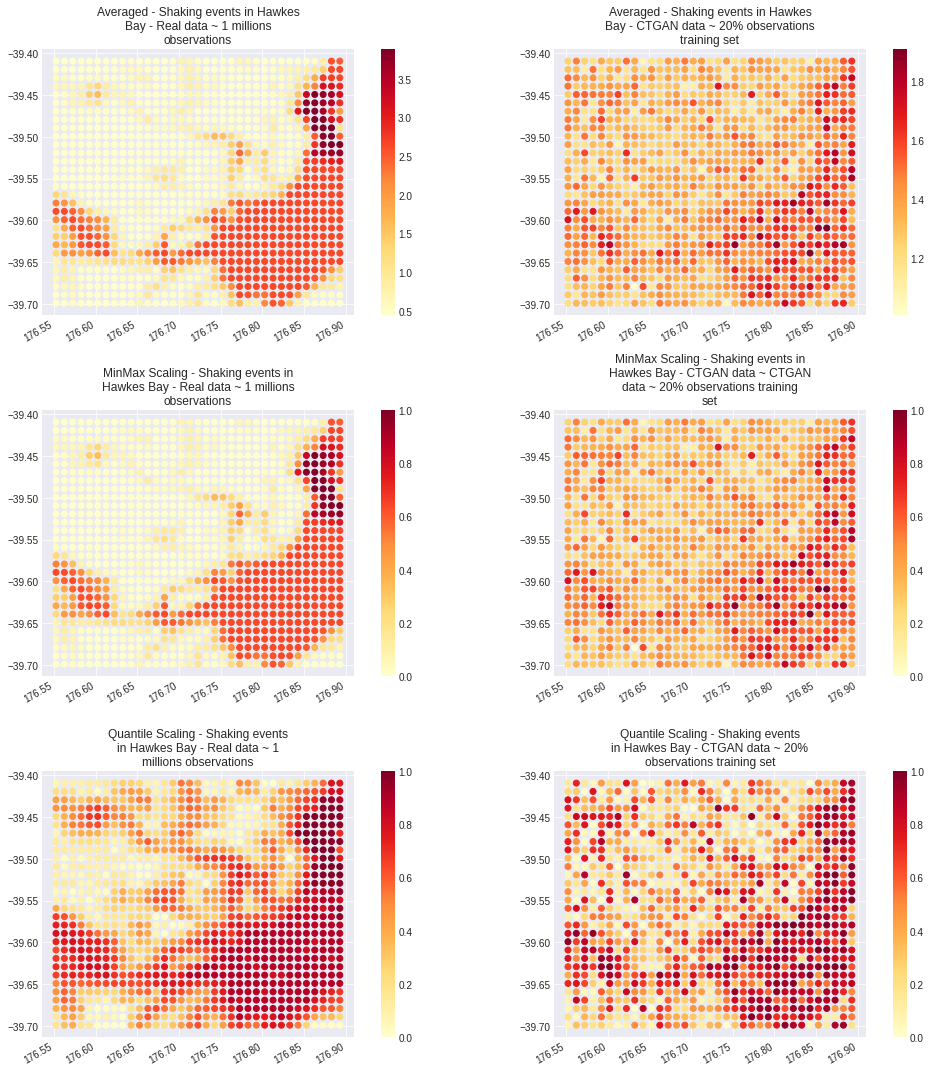

In [ ]:
# Mapping the patterns of PGA
mapping('Z2.5')

### 6.4.4. Mapping Z1.0

/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/usr/local/lib/python3.6/dist-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function 

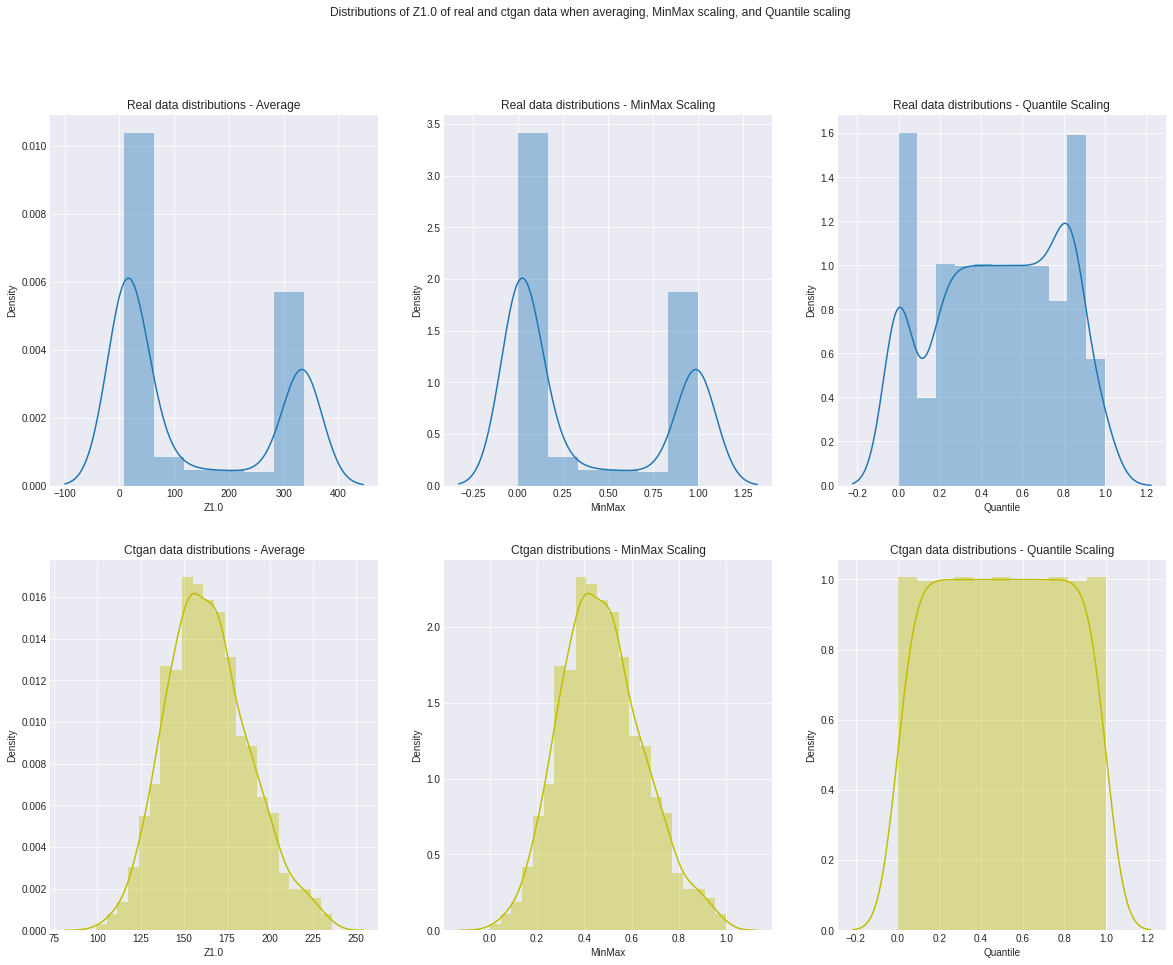

In [ ]:
# Plotting the distributions of PGA
dis_plot('Z1.0')

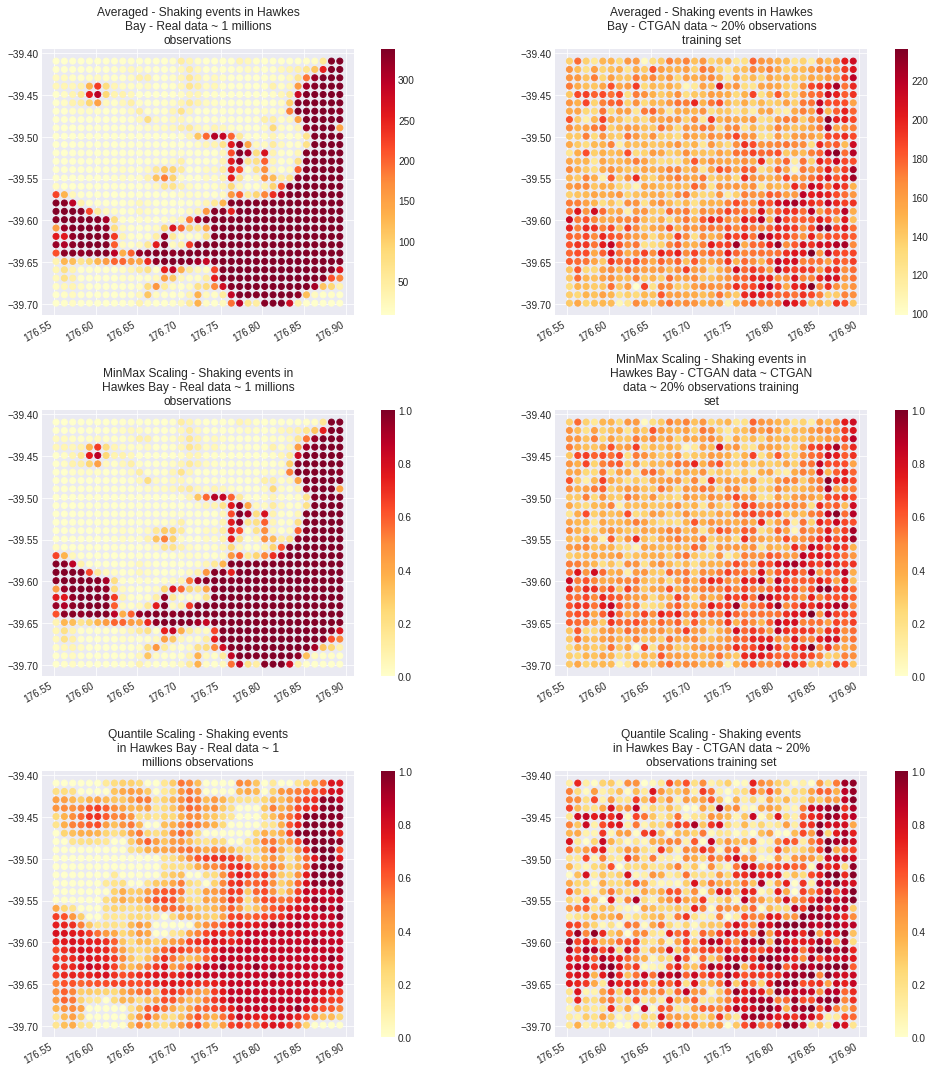

In [ ]:
# Mapping the patterns of PGA
mapping('Z1.0')